Com base na imagem enviada, a equação apresentada é a **equação do telégrafo** (ou *telegraph equation*) na forma:

$$\frac{\partial^2 u}{\partial t^2} + (\alpha + \beta)\frac{\partial u}{\partial t} + \alpha\beta u - c^2\frac{\partial^2 u}{\partial x^2} = 0$$

onde $\alpha$ e $\beta$ são constantes não negativas, $c$ é a velocidade de propagação e $u(x, t)$ representa, por exemplo, a tensão ou corrente ao longo de uma linha de transmissão com perdas e dispersão.

Abaixo está uma organização em seções e blocos de código em Python seguindo o estilo expositivo do notebook (com **SymPy** para a abordagem analítica/simbólica e **NumPy/SciPy/Matplotlib** para a resolução numérica e visualização).

---

## Resolução analítica (implementada computacionalmente)

Considere a equação do telégrafo no domínio espacial $0 < x < L$ e temporal $t > 0$, com condições de contorno homogêneas de Dirichlet:

$$u(0, t) = 0, \quad\quad u(L, t) = 0, \quad\quad t > 0,$$

e condições iniciais:

$$u(x, 0) = f(x), \quad\quad \frac{\partial u}{\partial t}(x, 0) = g(x), \quad\quad 0 < x < L.$$

### Definição simbólica e separação de variáveis

Supondo uma solução do tipo $u(x, t) = X(x)T(t)$ para o problema homogêneo, substituímos na EDP e dividimos por $c^2 X(x)T(t)$ para separar as variáveis espaciais e temporais.

In [1]:
import sympy as sp
sp.init_printing()

# definindo variáveis, parâmetros e funções simbólicas
x, t = sp.symbols('x t', real=True)
alpha, beta, c = sp.symbols('alpha beta c', positive=True, real=True)
lam = sp.symbols('lambda', positive=True, real=True)

u = sp.Function('u')(x, t)
X = sp.Function('X')(x)
T = sp.Function('T')(t)

# definindo a equação do telégrafo
eq_telegrafo = sp.Eq(
    sp.Derivative(u, t, 2)
    + (alpha + beta) * sp.Derivative(u, t)
    + alpha * beta * u
    - c**2 * sp.Derivative(u, x, 2),
    0
)
eq_telegrafo

                  2                                    2              
               2 ∂                      ∂             ∂               
α⋅β⋅u(x, t) - c ⋅───(u(x, t)) + (α + β)⋅──(u(x, t)) + ───(u(x, t)) = 0
                   2                    ∂t              2             
                 ∂x                                   ∂t              

In [2]:
# separando variáveis assumindo u(x, t) = X(x) * T(t)
u_sep = X * T
eq_sep = sp.expand(eq_telegrafo.lhs.subs(u, u_sep))

# isolando os termos em X e em T: (T'' + (a+b)T' + abT)/(c^2 T) = X''/X = -lambda
lado_x = sp.simplify(sp.Derivative(X, x, 2) / X)
lado_t = sp.simplify(
    (sp.Derivative(T, t, 2) + (alpha + beta) * sp.Derivative(T, t) + alpha * beta * T)
    / (c**2 * T)
)
lado_x, lado_t

⎛ 2                                        2       ⎞
⎜d                             d          d        ⎟
⎜───(X(x))  α⋅β⋅T(t) + (α + β)⋅──(T(t)) + ───(T(t))⎟
⎜  2                           dt           2      ⎟
⎜dx                                       dt       ⎟
⎜─────────, ───────────────────────────────────────⎟
⎜  X(x)                      2                     ⎟
⎝                           c ⋅T(t)                ⎠

### Problema espacial e autofunções

Com $\frac{X''}{X} = -\lambda$ ($\lambda > 0$) e as condições $X(0) = 0$ e $X(L) = 0$, obtemos os autovalores $\lambda_n = \left(\frac{n\pi}{L}\right)^2$ e as autofunções espaciais:

$$X_n(x) = \sin\left(\frac{n\pi x}{L}\right), \quad\quad n = 1, 2, 3, \dots$$

In [3]:
L = sp.symbols('L', positive=True, real=True)
n = sp.symbols('n', integer=True, positive=True)

# EDO espacial com autovalor lambda
eq_X = sp.Eq(sp.Derivative(X, x, 2), -lam * X)
sol_X_geral = sp.dsolve(eq_X, X, ics={X.subs(x, 0): 0})

# impondo X(L) = 0 => lambda_n = (n*pi/L)^2
lam_n = (n * sp.pi / L)**2
X_n = sp.sin(n * sp.pi * x / L)
sol_X_geral, lam_n, X_n

⎛                      2  2            ⎞
⎜                     π ⋅n      ⎛π⋅n⋅x⎞⎟
⎜X(x) = C₁⋅sin(√λ⋅x), ─────, sin⎜─────⎟⎟
⎜                       2       ⎝  L  ⎠⎟
⎝                      L               ⎠

### EDO temporal para cada modo $n$

Substituindo $\lambda = \lambda_n$ na equação temporal, temos a EDO linear de segunda ordem com coeficientes constantes:

$$T_n''(t) + (\alpha + \beta)T_n'(t) + \left(\alpha\beta + c^2\lambda_n\right)T_n(t) = 0.$$

O discriminante característico é:

$$\Delta_n = (\alpha + \beta)^2 - 4(\alpha\beta + c^2\lambda_n) = (\alpha - \beta)^2 - 4c^2\lambda_n.$$

In [4]:
# EDO temporal associada ao modo n
omega_n_sq = alpha * beta + c**2 * (n * sp.pi / L)**2
eq_T = sp.Eq(
    sp.Derivative(T, t, 2) + (alpha + beta) * sp.Derivative(T, t) + omega_n_sq * T,
    0
)
sol_T = sp.dsolve(eq_T, T)
sp.simplify(sol_T)

                                                                   ⎛           ↪
                                                                   ⎜           ↪
       ⎛         _______________________________________     ⎞     ⎜        ╲╱ ↪
       ⎜        ╱  2  2      2        2  2      2  2  2      ⎟  -t⋅⎜α + β + ── ↪
       ⎜    t⋅╲╱  L ⋅α  - 2⋅L ⋅α⋅β + L ⋅β  - 4⋅π ⋅c ⋅n       ⎟     ⎝           ↪
       ⎜    ────────────────────────────────────────────     ⎟  ────────────── ↪
       ⎜                         L                           ⎟                 ↪
T(t) = ⎝C₁⋅ℯ                                             + C₂⎠⋅ℯ               ↪

↪  _______________________________________⎞ 
↪ ╱  2  2      2        2  2      2  2  2 ⎟ 
↪   L ⋅α  - 2⋅L ⋅α⋅β + L ⋅β  - 4⋅π ⋅c ⋅n  ⎟ 
↪ ────────────────────────────────────────⎟ 
↪                   L                     ⎠ 
↪ ──────────────────────────────────────────
↪              2                            
↪                                   

### Construção da série truncada para condições iniciais específicas

Como exemplo concreto (alinhado aos parâmetros indicados na imagem, $\alpha = \beta = 0{,}25$, $c = 1$, e domínio $L = 4$), tomemos:

$$u(x, 0) = \sin\left(\frac{\pi x}{4}\right), \quad\quad \frac{\partial u}{\partial t}(x, 0) = 0.$$

Nesse caso, apenas o modo $n = 1$ é excitado diretamente pela condição inicial, e a solução analítica exata é dada em forma fechada (ou como série de Fourier):

In [5]:
# substituindo parâmetros numéricos para avaliação analítica: alpha = 0.25, beta = 0.25, c = 1, L = 4
params = {alpha: sp.Rational(1, 4), beta: sp.Rational(1, 4), c: 1, L: 4}

# para u(x, 0) = sin(pi*x/4) e u_t(x, 0) = 0, o coeficiente de Fourier é não nulo apenas para n = 1
a1 = 1
b1 = 0
eq_T1 = eq_T.subs({n: 1, **params})
sol_T1 = sp.dsolve(
    eq_T1,
    T,
    ics={T.subs(t, 0): a1, sp.Derivative(T, t).subs(t, 0): b1}
)
u_analitica_sim = sp.simplify(sol_T1.rhs * sp.sin(sp.pi * x / 4))
u_analitica_sim

                         -t          
                         ───         
⎛   ⎛π⋅t⎞        ⎛π⋅t⎞⎞   4     ⎛π⋅x⎞
⎜sin⎜───⎟ + π⋅cos⎜───⎟⎟⋅ℯ   ⋅sin⎜───⎟
⎝   ⎝ 4 ⎠        ⎝ 4 ⎠⎠         ⎝ 4 ⎠
─────────────────────────────────────
                  π                  

---

## Resolução numérica (diferenças finitas / método das linhas)

Para cenários mais gerais (como condições iniciais arbitrárias, termos não homogêneos ou coeficientes variáveis), podemos discretizar o espaço em $N_x$ pontos internos usando diferenças finitas centradas de segunda ordem e integrar o sistema resultante de EDOs no tempo com `scipy.integrate.solve_ivp`.

A discretização espacial em cada nó interior $x_i$ ($i = 1, \dots, N_x - 1$) com espaçamento $\Delta x$ é:

$$\frac{\partial^2 u}{\partial x^2}\Big\vert{}_{x_i, t} \approx \frac{u_{i+1}(t) - 2u_i(t) + u_{i-1}(t)}{\Delta x^2}.$$

Reescrevendo como um sistema de primeira ordem no tempo com $v_i(t) = \frac{du_i}{dt}$:

$$\begin{cases} \dfrac{du_i}{dt} = v_i, \\ \dfrac{dv_i}{dt} = c^2 \dfrac{u_{i+1} - 2u_i + u_{i-1}}{\Delta x^2} - (\alpha + \beta)v_i - \alpha\beta u_i. \end{cases}$$

In [6]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# parâmetros físicos e de malha
alpha_val = 0.25
beta_val = 0.25
c_val = 1.0
L_val = 4.0

Nx = 101
x_grid = np.linspace(0.0, L_val, Nx)
dx = x_grid[1] - x_grid[0]

# condições iniciais: u(x, 0) = sin(pi*x/4), u_t(x, 0) = 0
u0_interior = np.sin(np.pi * x_grid[1:-1] / L_val)
v0_interior = np.zeros_like(u0_interior)
y0 = np.concatenate([u0_interior, v0_interior])

n_int = len(u0_interior)

def rhs_telegrafo(t_curr, state):
    u_int = state[:n_int]
    v_int = state[n_int:]

    # condições de contorno homogêneas u(0, t) = 0 e u(L, t) = 0
    u_ext = np.concatenate(([0.0], u_int, [0.0]))
    d2u_dx2 = (u_ext[2:] - 2.0 * u_ext[1:-1] + u_ext[:-2]) / (dx**2)

    du_dt = v_int
    dv_dt = (
        c_val**2 * d2u_dx2
        - (alpha_val + beta_val) * v_int
        - alpha_val * beta_val * u_int
    )
    return np.concatenate([du_dt, dv_dt])

t_span = (0.0, 10.0)
t_eval = np.linspace(t_span[0], t_span[1], 201)

sol_num = solve_ivp(rhs_telegrafo, t_span, y0, t_eval=t_eval, method='RK45', rtol=1e-8, atol=1e-10)

# reconstruindo u(x, t) incluindo fronteiras
U_num = np.vstack([
    np.zeros((1, len(t_eval))),
    sol_num.y[:n_int, :],
    np.zeros((1, len(t_eval)))
])

### Comparação entre solução analítica e numérica

Erro máximo absoluto (analítica vs. numérica): 5.167e-05


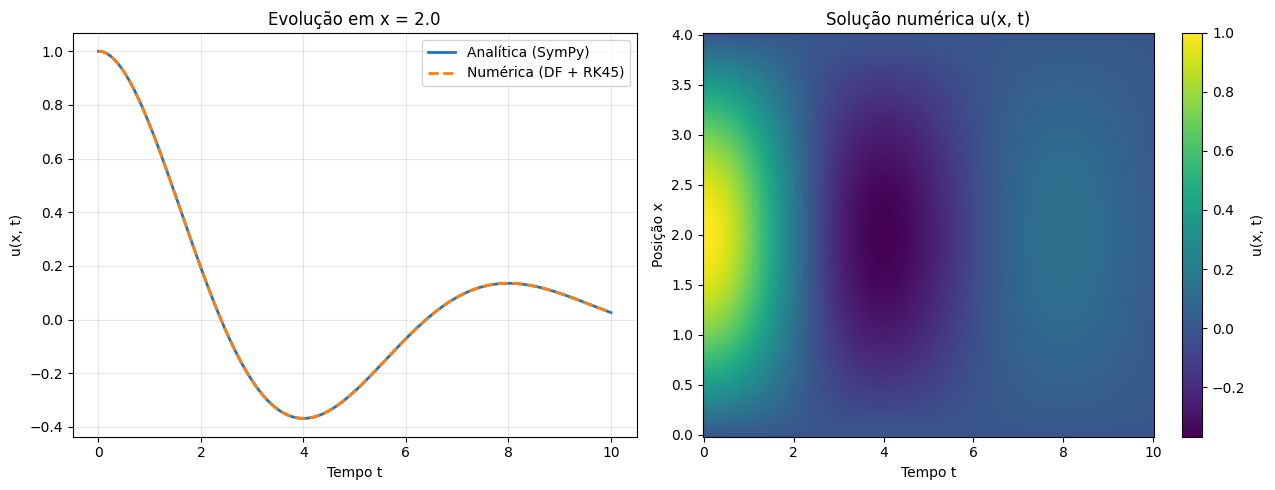

In [7]:
# avaliando a solução analítica na mesma malha (x, t)
u_analitica_func = sp.lambdify((x, t), u_analitica_sim, 'numpy')
XX, TT = np.meshgrid(x_grid, t_eval, indexing='ij')
U_ana = u_analitica_func(XX, TT)

erro_max = np.max(np.abs(U_num - U_ana))
print(f"Erro máximo absoluto (analítica vs. numérica): {erro_max:.3e}")

# visualizando a evolução temporal em x = 2.0 e a superfície (x, t)
idx_x = np.argmin(np.abs(x_grid - 2.0))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(t_eval, U_ana[idx_x, :], label='Analítica (SymPy)', lw=2)
axes[0].plot(t_eval, U_num[idx_x, :], '--', label='Numérica (DF + RK45)', lw=2)
axes[0].set_title(f'Evolução em x = {x_grid[idx_x]:.1f}')
axes[0].set_xlabel('Tempo t')
axes[0].set_ylabel('u(x, t)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

im = axes[1].pcolormesh(t_eval, x_grid, U_num, shading='auto', cmap='viridis')
axes[1].set_title('Solução numérica u(x, t)')
axes[1].set_xlabel('Tempo t')
axes[1].set_ylabel('Posição x')
fig.colorbar(im, ax=axes[1], label='u(x, t)')

plt.tight_layout()
plt.show()